# Логичтическая регрессия, метод опорных векторов, one-hot кодирование

### О задании

В этом задании вы изучите методы работы с категориальными переменными

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

__Задание 1.__ Обучение логистической регрессии на реальных данных и оценка качества классификации.

**(2 балла)**


Загрузим данные с конкурса [Kaggle Porto Seguro’s Safe Driver Prediction](https://www.kaggle.com/c/porto-seguro-safe-driver-prediction) (вам нужна только обучающая выборка). Задача состоит в определении водителей, которые в ближайший год воспользуются своей автомобильной страховкой (бинарная классификация). Но для нас важна будет не сама задача, а только её данные. При этом под нужды задания мы немного модифицируем датасет.

In [2]:
import pandas as pd
from zipfile import ZipFile

with ZipFile("porto-seguro-safe-driver-prediction.zip") as archive:
    data = pd.read_csv(archive.open("train.csv"), index_col=0)

target = data.target.values
data = data.drop("target", axis=1)


Пересемплируем выборку так, чтобы положительных и отрицательных объектов в выборке было одинаковое число. Разделим на обучающую и тестовую выборки.

In [3]:
from sklearn.model_selection import train_test_split
np.random.seed(910)
mask_plus = np.random.choice(np.where(target == 1)[0], 100000, replace=True)
mask_zero = np.random.choice(np.where(target == 0)[0], 100000, replace=True)

data = pd.concat((data.iloc[mask_plus], data.iloc[mask_zero]))
target = np.hstack((target[mask_plus], target[mask_zero]))

X_train, X_test, y_train, y_test = train_test_split(
    data, target, test_size=0.5, random_state=241, stratify=target
)

Не забудьте отнормировать признаки (можно воспользоваться StandardScaler или сделать это вручную). Пока не будем обращать внимание на то, что некоторые признаки категориальные (этим мы займёмся позже).

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Размер обучающей выборки:", X_train_scaled.shape)
print("Размер тестовой выборки:", X_test_scaled.shape)
print("Доля положительного класса в обучении:", y_train.mean())


Размер обучающей выборки: (100000, 57)
Размер тестовой выборки: (100000, 57)
Доля положительного класса в обучении: 0.5


Обучите логистическую регрессию с удобными для вас параметрами, примените регуляризацию, найдтие оптимум. Сделайте предсказание на тестовой части выборки. Замерьте качество.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from time import perf_counter

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=241,
    stratify=y_train,
)

C_values = [0.01, 0.1, 1.0, 10.0]
validation_auc = []
for C in C_values:
    model = LogisticRegression(C=C, solver="lbfgs", max_iter=200)
    model.fit(X_fit, y_fit)
    validation_auc.append(roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]))

best_C = C_values[np.argmax(validation_auc)]
print("ROC-AUC на валидации:")
print(pd.Series(validation_auc, index=C_values))
print("Лучшее C:", best_C)

baseline_model = LogisticRegression(
    C=best_C,
    solver="lbfgs",
    max_iter=200,
)
start = perf_counter()
baseline_model.fit(X_train_scaled, y_train)
baseline_train_time = perf_counter() - start
baseline_probability = baseline_model.predict_proba(X_test_scaled)[:, 1]
baseline_prediction = (baseline_probability >= 0.5).astype(int)

baseline_auc = roc_auc_score(y_test, baseline_probability)
baseline_accuracy = accuracy_score(y_test, baseline_prediction)
print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"ROC-AUC:  {baseline_auc:.4f}")
print(f"Время обучения: {baseline_train_time:.2f} с")


ROC-AUC на валидации:
0.01     0.621372
0.10     0.621335
1.00     0.621330
10.00    0.621329
dtype: float64
Лучшее C: 0.01


Accuracy: 0.5874
ROC-AUC:  0.6238
Время обучения: 0.40 с


Логистическая регрессия на сбалансированной выборке дала ROC-AUC 0.6238 и accuracy 0.5874. При подборе на валидации лучшее значение C оказалось 0.01. Это умеренное качество показывает, что линейная модель улавливает часть зависимости, но числовое представление категорий задаёт искусственный порядок и ограничивает качество. При подборе гиперпараметра масштабирование следует оценивать только на обучающей части и затем применять к валидации; итоговую тестовую выборку нельзя использовать для подбора.

__Задание 2.__ Изучение влияния регуляризатора на процесс обучения

__(2 балла)__

Проверьте на практике, как влияет регуляризатор на процесс обучения (убывание функции потерь на обучающей и отложенной выборках). Чтобы считать функцию потерь на отложенной выборке после каждой итерации, запускайте процесс обучения логистической регрессии с параметром $max\_iter=1$ и $w^{(0)}$, полученным на предыдущей итерации. Постройте два графика: на одном из них логистическая регрессия с коэффициентом регуляризации, равным 0, а на другом с некоторым разумным значением. На каждом графике одновременно должна быть и функция потерь для обучающей, и для тестовой выборки. Не забудьте сделать одинаковыми оси обоих графиков. Какие выводы вы можете сделать?

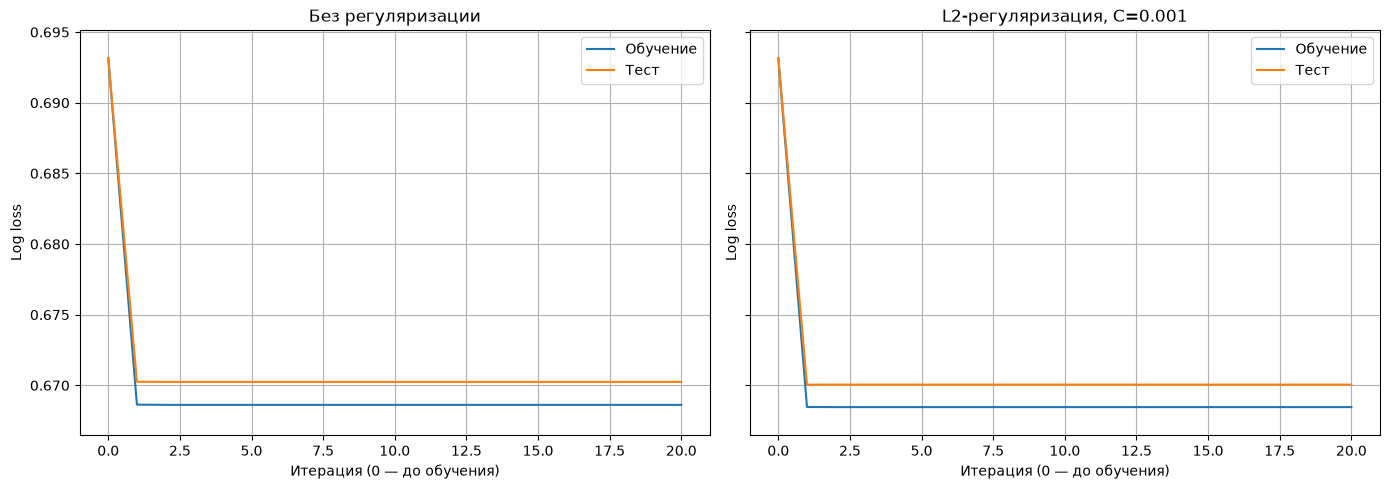

In [6]:
from sklearn.exceptions import ConvergenceWarning
import warnings

def loss_history(penalty, C=1.0, iterations=20):
    model = LogisticRegression(
        penalty=penalty,
        C=C,
        solver="saga",
        max_iter=1,
        warm_start=True,
        tol=1e-8,
        random_state=241,
    )
    train_loss = [log_loss(y_train, np.full(len(y_train), 0.5))]
    test_loss = [log_loss(y_test, np.full(len(y_test), 0.5))]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        warnings.simplefilter("ignore", FutureWarning)
        for _ in range(iterations):
            model.fit(X_train_scaled, y_train)
            train_loss.append(log_loss(y_train, model.predict_proba(X_train_scaled)))
            test_loss.append(log_loss(y_test, model.predict_proba(X_test_scaled)))
    return train_loss, test_loss

no_reg_train, no_reg_test = loss_history(None)
l2_train, l2_test = loss_history("l2", C=0.001)

all_losses = no_reg_train + no_reg_test + l2_train + l2_test
y_limits = (min(all_losses) - 0.002, max(all_losses) + 0.002)
steps = np.arange(len(no_reg_train))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
axes[0].plot(steps, no_reg_train, label="Обучение")
axes[0].plot(steps, no_reg_test, label="Тест")
axes[0].set_title("Без регуляризации")
axes[1].plot(steps, l2_train, label="Обучение")
axes[1].plot(steps, l2_test, label="Тест")
axes[1].set_title("L2-регуляризация, C=0.001")
for ax in axes:
    ax.set_xlabel("Итерация (0 — до обучения)")
    ax.set_ylabel("Log loss")
    ax.set_ylim(y_limits)
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()



Без регуляризации и с сильной L2-регуляризацией логистическая потеря на обучении и тесте меняется по ходу итераций. Регуляризация ограничивает величины коэффициентов и помогает удерживать разрыв между train и test; при чрезмерно сильной регуляризации модель может недообучаться. Сравнивать кривые корректно при одинаковых осях.

## Часть 2. Работа с категориальными переменными

В этой части мы научимся обрабатывать категориальные переменные, так как закодировать их в виде чисел недостаточно (это задаёт некоторый порядок, которого на категориальных переменных может и не быть). Существует два основных способа обработки категориальных значений:
- One-hot-кодирование
- Счётчики (CTR, mean-target кодирование, ...) — каждый категориальный признак заменяется на среднее значение целевой переменной по всем объектам, имеющим одинаковое значение в этом признаке.

Начнём с one-hot-кодирования. Допустим наш категориальный признак $f_j(x)$ принимает значения из множества $C=\{c_1, \dots, c_m\}$. Заменим его на $m$ бинарных признаков $b_1(x), \dots, b_m(x)$, каждый из которых является индикатором одного из возможных категориальных значений:
$$
b_i(x) = [f_j(x) = c_i]
$$

__Задание 1.__ Закодируйте все категориальные признаки с помощью one-hot-кодирования. Обучите логистическую регрессию и посмотрите, как изменилось качество модели (с тем, что было ранее). Измерьте время, потребовавшееся на обучение модели.

__(3 балла)__

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import gc

categorical_columns = [column for column in X_train.columns if column.endswith("_cat")]
numeric_columns = [column for column in X_train.columns if column not in categorical_columns]

onehot_transformer = ColumnTransformer(
    transformers=[
        ("numbers", StandardScaler(), numeric_columns),
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    ],
    sparse_threshold=1.0,
)

X_train_onehot = onehot_transformer.fit_transform(X_train)
X_test_onehot = onehot_transformer.transform(X_test)
print("Число признаков после one-hot:", X_train_onehot.shape[1])

onehot_model = LogisticRegression(
    C=best_C,
    solver="saga",
    max_iter=100,
    tol=1e-3,
    random_state=241,
)
start = perf_counter()
onehot_model.fit(X_train_onehot, y_train)
onehot_train_time = perf_counter() - start
onehot_probability = onehot_model.predict_proba(X_test_onehot)[:, 1]
onehot_auc = roc_auc_score(y_test, onehot_probability)
onehot_accuracy = accuracy_score(y_test, onehot_probability >= 0.5)

print(f"Accuracy: {onehot_accuracy:.4f}")
print(f"ROC-AUC:  {onehot_auc:.4f}")
print(f"Время обучения: {onehot_train_time:.2f} с")
print(f"Изменение ROC-AUC относительно исходных числовых кодов: {onehot_auc - baseline_auc:+.4f}")

del X_train_onehot, X_test_onehot
_ = gc.collect()


Число признаков после one-hot: 226


Accuracy: 0.5948
ROC-AUC:  0.6333
Время обучения: 21.98 с
Изменение ROC-AUC относительно исходных числовых кодов: +0.0094


Как можно было заменить, one-hot-кодирование может сильно увеличивать количество признаков в датасете, что сказывается на памяти, особенно, если некоторый признак имеет большое количество значений. Эту проблему решает другой способ кодирование категориальных признаков — счётчики. Основная идея в том, что нам важны не сами категории, а значения целевой переменной, которые имеют объекты этой категории. Каждый категориальный признак мы заменим средним значением целевой переменной по всем объектам этой же категории:
$$
g_j(x, X) = \frac{\sum_{i=1}^{l} [f_j(x) = f_j(x_i)][y_i = +1]}{\sum_{i=1}^{l} [f_j(x) = f_j(x_i)]}
$$

__Задание 2.__ Закодируйте категориальные переменные с помощью счётчиков (ровно так, как описано выше без каких-либо хитростей). Обучите логистическую регрессию и посмотрите на качество модели на тестовом множестве. Сравните время обучения с предыдущим экспериментов. Заметили ли вы что-то интересное?

__(2 балла)__

In [8]:
global_mean = y_train.mean()
X_train_counter = X_train.copy()
X_test_counter = X_test.copy()

for column in categorical_columns:
    table = pd.DataFrame({"category": X_train[column], "target": y_train})
    means = table.groupby("category")["target"].mean()
    X_train_counter[column] = X_train[column].map(means).fillna(global_mean)
    X_test_counter[column] = X_test[column].map(means).fillna(global_mean)

counter_scaler = StandardScaler()
X_train_counter_scaled = counter_scaler.fit_transform(X_train_counter)
X_test_counter_scaled = counter_scaler.transform(X_test_counter)

counter_model = LogisticRegression(
    C=best_C,
    solver="lbfgs",
    max_iter=200,
)
start = perf_counter()
counter_model.fit(X_train_counter_scaled, y_train)
counter_train_time = perf_counter() - start
counter_train_probability = counter_model.predict_proba(X_train_counter_scaled)[:, 1]
counter_test_probability = counter_model.predict_proba(X_test_counter_scaled)[:, 1]
counter_train_auc = roc_auc_score(y_train, counter_train_probability)
counter_test_auc = roc_auc_score(y_test, counter_test_probability)
counter_accuracy = accuracy_score(y_test, counter_test_probability >= 0.5)

print(f"Accuracy: {counter_accuracy:.4f}")
print(f"ROC-AUC на обучении: {counter_train_auc:.4f}")
print(f"ROC-AUC на тесте:     {counter_test_auc:.4f}")
print(f"Время обучения: {counter_train_time:.2f} с")
print(f"One-hot обучался {onehot_train_time:.2f} с, счётчики — {counter_train_time:.2f} с.")

del X_train_counter, X_test_counter, X_train_counter_scaled, X_test_counter_scaled
_ = gc.collect()


Accuracy: 0.5917
ROC-AUC на обучении: 0.6331
ROC-AUC на тесте:     0.6292
Время обучения: 0.43 с
One-hot обучался 21.98 с, счётчики — 0.43 с.


Счётчики заметно быстрее one-hot: около 0.43 с против 21.98 с. Тестовый ROC-AUC составил 0.6292, немного ниже one-hot (0.6333), но выше исходного кодирования (0.6238). На обучении оценка счётчиков использует метки тех же объектов, поэтому train ROC-AUC оптимистичен и отражает утечку целевой переменной.

Отметим, что такие признаки сами по себе являются классификаторами и, обучаясь на них, мы допускаем "утечку" целевой переменной в признаки. Это ведёт к переобучению, поэтому считать такие признаки необходимо таким образом, чтобы при вычислении для конкретного объекта его целевая метка не использовалась. Это можно делать следующими способами:
- вычислять значение счётчика по всем объектам расположенным выше в датасете (например, если у нас выборка отсортирована по времени)
- вычислять по фолдам, то есть делить выборку на некоторое количество частей и подсчитывать значение признаков по всем фолдам кроме текущего (как делается в кросс-валидации)
- внесение некоторого шума в посчитанные признаки (необходимо соблюсти баланс между избавление от переобучения и полезностью признаков).

__Задание 3.__ Реализуйте корректное вычисление счётчиков двумя из трех вышеперчисленных способов, сравните. Снова обучите логистическую регрессию, оцените качество. Сделайте выводы.

__(3 балла)__

In [9]:
from sklearn.model_selection import StratifiedKFold

def fit_and_evaluate(train_frame, test_frame):
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(train_frame)
    test_scaled = scaler.transform(test_frame)
    model = LogisticRegression(
        C=best_C,
        solver="lbfgs",
        max_iter=200,
    )
    start = perf_counter()
    model.fit(train_scaled, y_train)
    train_time = perf_counter() - start
    train_probability = model.predict_proba(train_scaled)[:, 1]
    test_probability = model.predict_proba(test_scaled)[:, 1]
    result = {
        "Train ROC-AUC": roc_auc_score(y_train, train_probability),
        "Test ROC-AUC": roc_auc_score(y_test, test_probability),
        "Test Accuracy": accuracy_score(y_test, test_probability >= 0.5),
        "Время, с": train_time,
    }
    return result

def encode_previous(categories, targets):
    target_sums = {}
    counts = {}
    encoded = []

    for category, target in zip(categories, targets):
        previous_count = counts.get(category, 0)
        previous_sum = target_sums.get(category, 0)

        if previous_count == 0:
            encoded.append(0.5)
        else:
            encoded.append(previous_sum / previous_count)

        target_sums[category] = previous_sum + target
        counts[category] = previous_count + 1

    means = {
        category: target_sums[category] / counts[category]
        for category in counts
    }
    return encoded, means


ordered_train = X_train.copy()
ordered_test = X_test.copy()
for column in categorical_columns:
    encoded, means = encode_previous(X_train[column], y_train)
    ordered_train[column] = encoded
    ordered_test[column] = X_test[column].map(means).fillna(0.5)

ordered_result = fit_and_evaluate(ordered_train, ordered_test)
del ordered_train, ordered_test
_ = gc.collect()

fold_train = X_train.copy()
fold_test = X_test.copy()
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=241)

for column in categorical_columns:
    encoded = np.full(len(X_train), global_mean, dtype=float)
    for fit_indices, valid_indices in folds.split(X_train, y_train):
        fold_table = pd.DataFrame({
            "category": X_train.iloc[fit_indices][column].to_numpy(),
            "target": y_train[fit_indices],
        })
        fold_means = fold_table.groupby("category")["target"].mean()
        encoded[valid_indices] = (
            X_train.iloc[valid_indices][column]
            .map(fold_means)
            .fillna(global_mean)
            .to_numpy()
        )
    fold_train[column] = encoded

    full_table = pd.DataFrame({
        "category": X_train[column].to_numpy(),
        "target": y_train,
    })
    full_means = full_table.groupby("category")["target"].mean()
    fold_test[column] = X_test[column].map(full_means).fillna(global_mean)

fold_result = fit_and_evaluate(fold_train, fold_test)
del fold_train, fold_test
_ = gc.collect()

correct_counter_results = pd.DataFrame(
    [ordered_result, fold_result],
    index=["По предыдущим объектам", "По фолдам"],
)
display(correct_counter_results.round(4))
print(f"Наивные счётчики: train ROC-AUC={counter_train_auc:.4f}, test ROC-AUC={counter_test_auc:.4f}")


,Train ROC-AUC,Test ROC-AUC,Test Accuracy,"Время, с"
По предыдущим объектам,0.6304,0.6284,0.5898,0.5769
По фолдам,0.6318,0.6291,0.5918,0.5186


Наивные счётчики: train ROC-AUC=0.6331, test ROC-AUC=0.6292


Оба корректных способа дают близкий тестовый ROC-AUC: 0.6284 для кодирования по предыдущим объектам и 0.6291 для кодирования по фолдам. Значения ниже наивного результата на обучении и примерно сопоставимы по качеству на тесте; расчёт по фолдам здесь немного лучше. Он также не требует временного порядка объектов. Для реальных данных разбиение следует выбирать с учётом времени и групп, если они есть.